**ROLL NO : 24BAD087**  
**NAME : POOVIKA M**

**EXP NO : 7**

**GENERATE SYNTHETIC IMAGES USING A GENERATIVE ADVERSARIAL NETWORK (GAN)**

Part A: Dataset Preparation and Image Preprocessing

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Number of training images: 60000
Image dimensions: (28, 28)
Pixel value range before normalization: 0 to 255


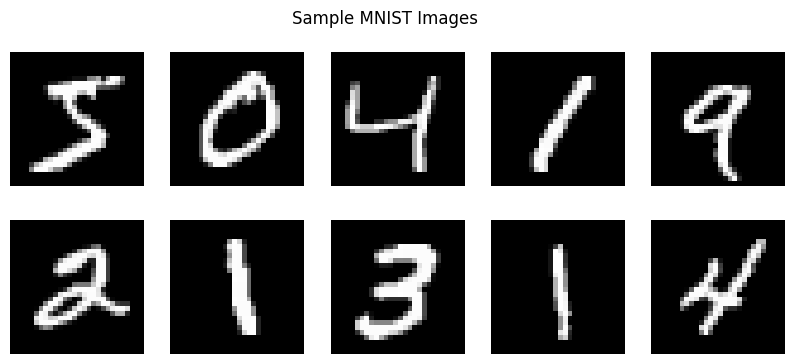

Shape after preprocessing: (60000, 28, 28, 1)
Pixel value range after normalization: -1.0 to 1.0
Dataset prepared successfully.


In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load MNIST dataset
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

# Display dataset information
print("Number of training images:", x_train.shape[0])
print("Image dimensions:", x_train.shape[1:])
print("Pixel value range before normalization:", x_train.min(), "to", x_train.max())

# Display sample images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.axis("off")
plt.suptitle("Sample MNIST Images")
plt.show()

# Normalize pixel values to [-1, 1]
x_train = x_train.astype("float32")
x_train = (x_train - 127.5) / 127.5

# Reshape images to include channel dimension
x_train = np.expand_dims(x_train, axis=-1)

print("Shape after preprocessing:", x_train.shape)
print("Pixel value range after normalization:",
      x_train.min(), "to", x_train.max())

# Create TensorFlow dataset
BATCH_SIZE = 128

train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
train_dataset = train_dataset.shuffle(60000).batch(BATCH_SIZE, drop_remainder=True)

print("Dataset prepared successfully.")

Part B: Implementing the Generator

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,600 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,944 (8.89 MB)

 Trainable params: 2,305,472 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

Generated image shape: (1, 28, 28, 1)


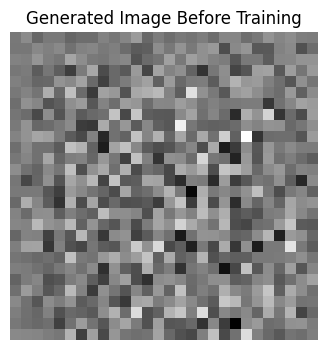

In [2]:
from tensorflow.keras import layers

# Define noise dimension
NOISE_DIM = 100

# Build Generator
generator = tf.keras.Sequential([
    layers.Input(shape=(NOISE_DIM,)),

    layers.Dense(7 * 7 * 256, use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(),

    layers.Reshape((7, 7, 256)),

    layers.Conv2DTranspose(
        128, (5, 5),
        strides=(1, 1),
        padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.LeakyReLU(),

    layers.Conv2DTranspose(
        64, (5, 5),
        strides=(2, 2),
        padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.LeakyReLU(),

    layers.Conv2DTranspose(
        1, (5, 5),
        strides=(2, 2),
        padding="same",
        use_bias=False,
        activation="tanh"
    )
])

# Display Generator architecture
generator.summary()

# Generate an image before training
noise = tf.random.normal([1, NOISE_DIM])
generated_image = generator(noise, training=False)

print("Generated image shape:", generated_image.shape)

# Display generated image
plt.figure(figsize=(4, 4))
plt.imshow(generated_image[0, :, :, 0], cmap="gray")
plt.axis("off")
plt.title("Generated Image Before Training")
plt.show()

Part C: Implementing the Discriminator and GAN Model

In [3]:
# Build Discriminator
discriminator = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(64, (5, 5), strides=(2, 2), padding="same"),
    layers.LeakyReLU(),
    layers.Dropout(0.3),

    layers.Conv2D(128, (5, 5), strides=(2, 2), padding="same"),
    layers.LeakyReLU(),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(1)
])

# Display Discriminator
discriminator.summary()

# Compile Discriminator
discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002
)

discriminator.compile(
    optimizer=discriminator_optimizer,
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

# Create GAN model
gan_input = layers.Input(shape=(NOISE_DIM,))
gan_output = discriminator(generator(gan_input))

gan = tf.keras.Model(gan_input, gan_output)

gan_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002
)

gan.compile(
    optimizer=gan_optimizer,
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True)
)

print("GAN model created successfully.")

print("\nGenerator Summary:")
generator.summary()

print("\nDiscriminator Summary:")
discriminator.summary()

print("\nGAN Summary:")
gan.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

GAN model created successfully.

Generator Summary:


... (13 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 28, 28, 1)      │     2,330,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 1)              │       212,865 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,543,809 (9.70 MB)

 Trainable params: 2,518,337 (9.61 MB)

 Non-trainable params: 25,472 (99.50 KB)

Part D: GAN Training and Synthetic Image Generation

Epoch 1/20 | Discriminator Loss: 1.0661 | Generator Loss: 1.3505


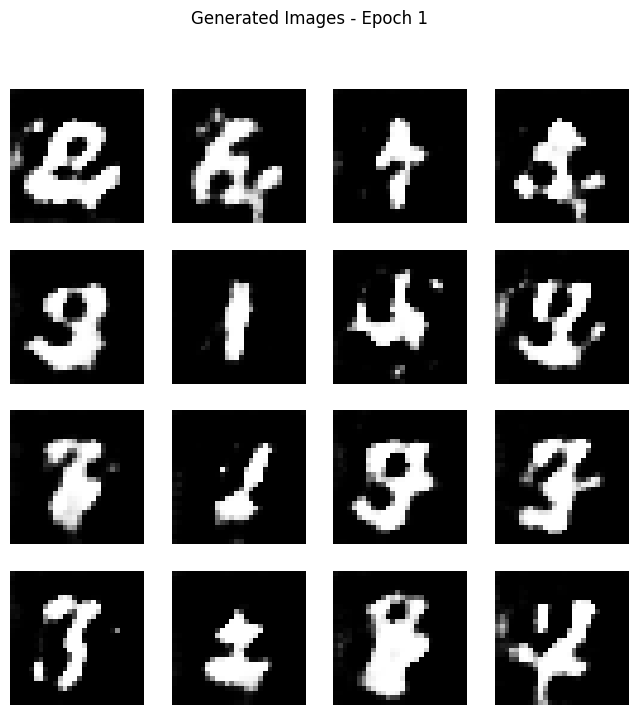

Epoch 2/20 | Discriminator Loss: 1.0209 | Generator Loss: 1.4545
Epoch 3/20 | Discriminator Loss: 1.0079 | Generator Loss: 1.4135
Epoch 4/20 | Discriminator Loss: 0.9901 | Generator Loss: 1.4891
Epoch 5/20 | Discriminator Loss: 0.9518 | Generator Loss: 1.5605


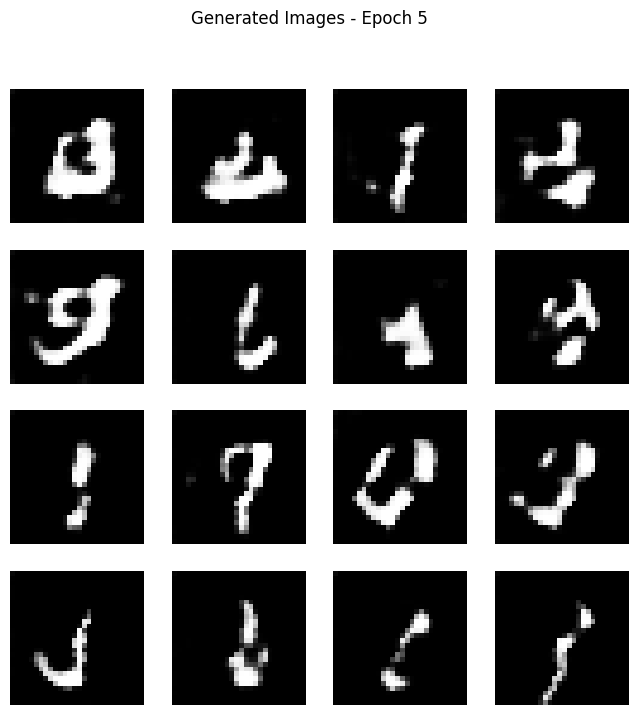

Epoch 6/20 | Discriminator Loss: 0.9464 | Generator Loss: 1.5534
Epoch 7/20 | Discriminator Loss: 0.9581 | Generator Loss: 1.5612
Epoch 8/20 | Discriminator Loss: 1.0104 | Generator Loss: 1.4972
Epoch 9/20 | Discriminator Loss: 1.0209 | Generator Loss: 1.4306
Epoch 10/20 | Discriminator Loss: 1.0819 | Generator Loss: 1.3013


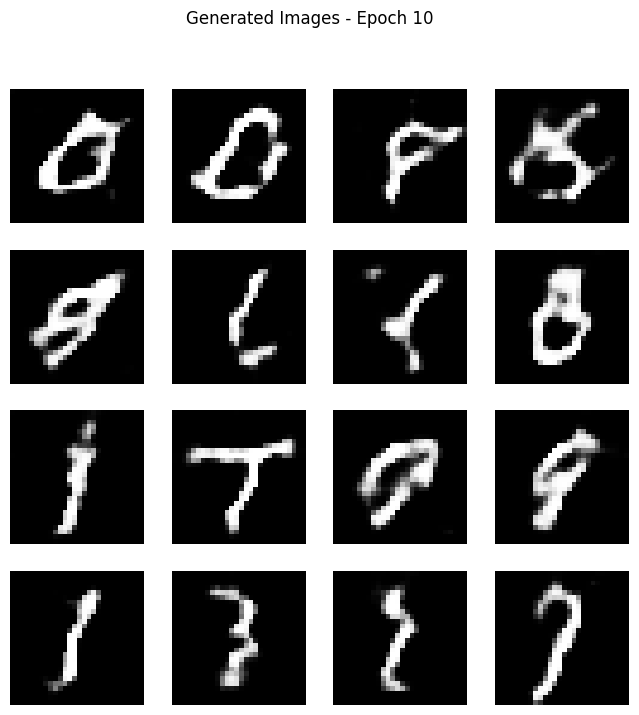

Epoch 11/20 | Discriminator Loss: 1.0927 | Generator Loss: 1.3147
Epoch 12/20 | Discriminator Loss: 1.1157 | Generator Loss: 1.2745
Epoch 13/20 | Discriminator Loss: 1.1076 | Generator Loss: 1.2366
Epoch 14/20 | Discriminator Loss: 1.1422 | Generator Loss: 1.1582
Epoch 15/20 | Discriminator Loss: 1.1363 | Generator Loss: 1.2601


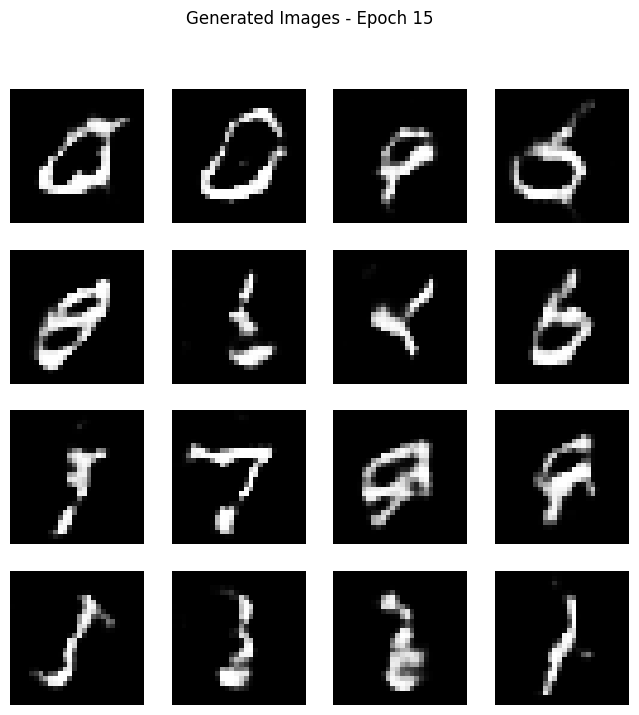

Epoch 16/20 | Discriminator Loss: 1.1544 | Generator Loss: 1.1260
Epoch 17/20 | Discriminator Loss: 1.1672 | Generator Loss: 1.1392
Epoch 18/20 | Discriminator Loss: 1.1704 | Generator Loss: 1.1056
Epoch 19/20 | Discriminator Loss: 1.1857 | Generator Loss: 1.0855
Epoch 20/20 | Discriminator Loss: 1.1700 | Generator Loss: 1.1169


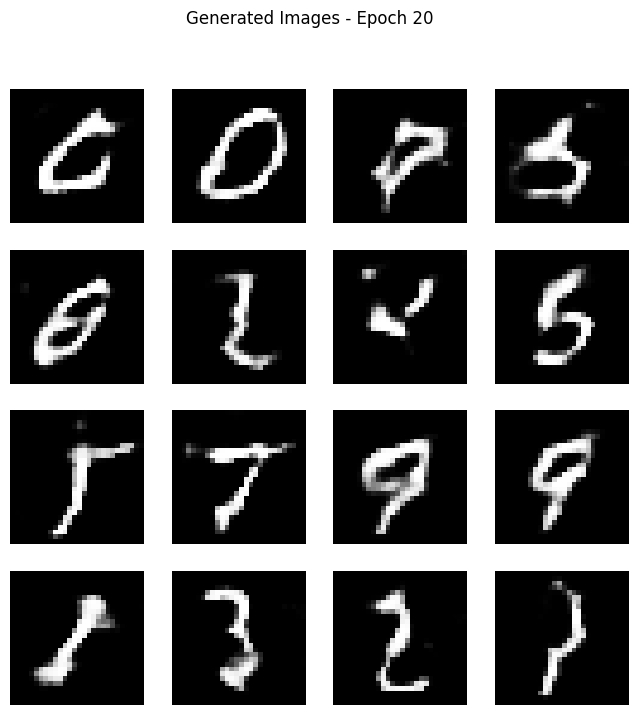

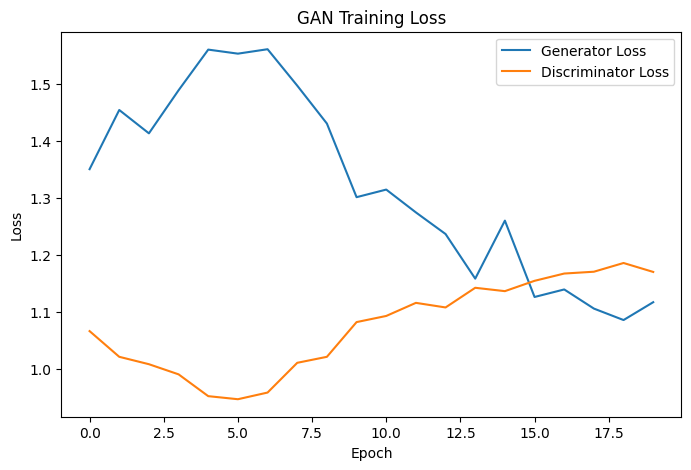

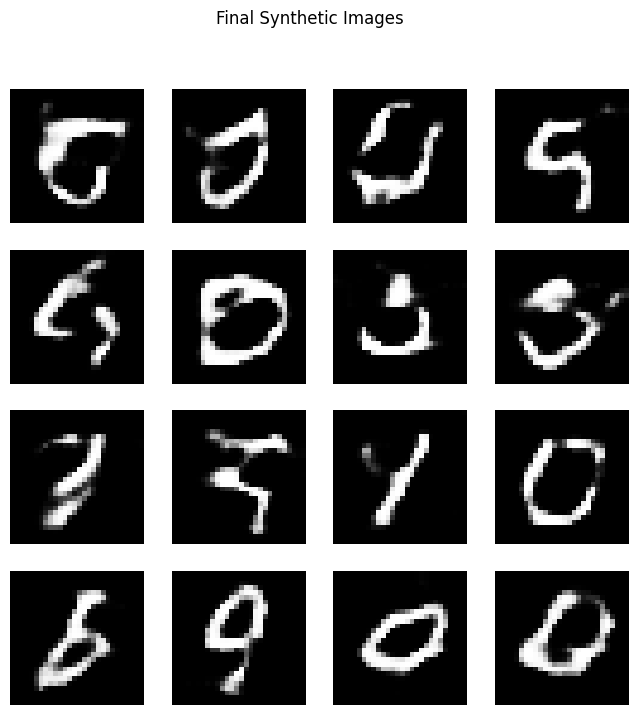

Final synthetic images saved successfully.


In [5]:
# Training parameters
EPOCHS = 20
NUM_EXAMPLES = 16

generator_losses = []
discriminator_losses = []

# Fixed noise for observing progress
seed = tf.random.normal([NUM_EXAMPLES, NOISE_DIM])

# Training loop
for epoch in range(EPOCHS):

    d_losses = []
    g_losses = []

    for real_images in train_dataset:

        batch_size = tf.shape(real_images)[0]

        # Generate random noise
        noise = tf.random.normal([batch_size, NOISE_DIM])

        # Generate fake images
        fake_images = generator(noise, training=True)

        # Labels
        real_labels = tf.ones((batch_size, 1))
        fake_labels = tf.zeros((batch_size, 1))

        # Train Discriminator
        with tf.GradientTape() as tape:
            real_output = discriminator(real_images, training=True)
            fake_output = discriminator(fake_images, training=True)

            real_loss = tf.keras.losses.binary_crossentropy(
                real_labels, real_output, from_logits=True
            )

            fake_loss = tf.keras.losses.binary_crossentropy(
                fake_labels, fake_output, from_logits=True
            )

            d_loss = tf.reduce_mean(real_loss + fake_loss)

        gradients = tape.gradient(
            d_loss, discriminator.trainable_variables
        )

        discriminator_optimizer.apply_gradients(
            zip(gradients, discriminator.trainable_variables)
        )

        # Train Generator
        noise = tf.random.normal([batch_size, NOISE_DIM])

        with tf.GradientTape() as tape:
            generated_images = generator(noise, training=True)
            generated_output = discriminator(
                generated_images, training=True
            )

            g_loss = tf.reduce_mean(
                tf.keras.losses.binary_crossentropy(
                    real_labels,
                    generated_output,
                    from_logits=True
                )
            )

        gradients = tape.gradient(
            g_loss, generator.trainable_variables
        )

        gan_optimizer.apply_gradients(
            zip(gradients, generator.trainable_variables)
        )

        d_losses.append(float(d_loss))
        g_losses.append(float(g_loss))

    # Store average losses
    avg_d_loss = np.mean(d_losses)
    avg_g_loss = np.mean(g_losses)

    discriminator_losses.append(avg_d_loss)
    generator_losses.append(avg_g_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Discriminator Loss: {avg_d_loss:.4f} | "
        f"Generator Loss: {avg_g_loss:.4f}"
    )

    # Display generated images every 5 epochs
    if (epoch + 1) % 5 == 0 or epoch == 0:

        predictions = generator(seed, training=False)

        plt.figure(figsize=(8, 8))

        for i in range(NUM_EXAMPLES):
            plt.subplot(4, 4, i + 1)
            plt.imshow(predictions[i, :, :, 0], cmap="gray")
            plt.axis("off")

        plt.suptitle(f"Generated Images - Epoch {epoch + 1}")
        plt.show()

# Plot Generator and Discriminator losses
plt.figure(figsize=(8, 5))
plt.plot(generator_losses, label="Generator Loss")
plt.plot(discriminator_losses, label="Discriminator Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.show()

# Generate final synthetic images
final_noise = tf.random.normal([16, NOISE_DIM])
final_images = generator(final_noise, training=False)

plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(final_images[i, :, :, 0], cmap="gray")
    plt.axis("off")

plt.suptitle("Final Synthetic Images")
plt.show()

# Save final generated images
for i in range(16):
    image = final_images[i, :, :, 0].numpy()
    image = ((image + 1) * 127.5).astype(np.uint8)
    tf.keras.utils.save_img(
        f"generated_image_{i + 1}.png",
        image[..., np.newaxis]
    )

print("Final synthetic images saved successfully.")